In [3]:
# Load application keys & audit all 6 relational tables
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [4]:
DATA_DIR = Path("../data/raw")
app_train = pd.read_csv(DATA_DIR / "application_train.csv", usecols=["SK_ID_CURR", "TARGET"])
train_ids = set(app_train["SK_ID_CURR"])

relational_files = {
    "bureau": "bureau.csv",
    "bureau_balance": "bureau_balance.csv",
    "previous_application": "previous_application.csv",
    "installments_payments": "installments_payments.csv",
    "POS_CASH_balance": "POS_CASH_balance.csv",
    "credit_card_balance": "credit_card_balance.csv",
}

In [5]:
audit_rows = []
for name, filename in relational_files.items():
    df_rel = pd.read_csv(DATA_DIR / filename)
    has_curr = "SK_ID_CURR" in df_rel.columns
    if has_curr:
        matched_ids = set(df_rel["SK_ID_CURR"]).intersection(train_ids)
        coverage = len(matched_ids) / len(train_ids)
        avg_records = len(df_rel[df_rel["SK_ID_CURR"].isin(train_ids)]) / max(len(matched_ids), 1)
    else:
        coverage = np.nan
        avg_records = np.nan

    # Check for 365243 placeholder in any DAYS_* columns
    days_cols = [c for c in df_rel.columns if c.startswith("DAYS_")]
    anom_cols = [c for c in days_cols if (df_rel[c] == 365243).any()]

    audit_rows.append({
        "table": name,
        "rows": f"{len(df_rel):,}",
        "cols": df_rel.shape[1],
        "train_coverage": f"{coverage:.1%}" if pd.notna(coverage) else "via SK_ID_BUREAU",
        "avg_rows_per_client": round(avg_records, 1) if pd.notna(avg_records) else np.nan,
        "days_365243_cols": ", ".join(anom_cols) if anom_cols else "None",
    })

pd.DataFrame(audit_rows)

,table,rows,cols,train_coverage,avg_rows_per_client,days_365243_cols
0,bureau,"1,716,428",17,85.7%,5.6,None
1,bureau_balance,"27,299,925",3,via SK_ID_BUREAU,NaN,None
2,previous_application,"1,670,214",37,94.6%,4.9,"DAYS_FIRST_DRAWING, DAYS_FIRST_DUE, DAYS_LAST_..."
3,installments_payments,"13,605,401",8,94.8%,39.7,None
4,POS_CASH_balance,"10,001,358",8,94.1%,29.5,None
5,credit_card_balance,"3,840,312",23,28.3%,37.1,None


In [6]:
# Check whether having history in each table correlates with TARGET
presence_rows = []
for name in ["bureau", "previous_application", "installments_payments", "POS_CASH_balance", "credit_card_balance"]:
    ids_in_table = set(pd.read_csv(DATA_DIR / f"{name}.csv", usecols=["SK_ID_CURR"])["SK_ID_CURR"])
    has_record = app_train["SK_ID_CURR"].isin(ids_in_table)
    presence_rows.append({
        "table": name,
        "coverage": f"{has_record.mean():.1%}",
        "default_if_present": f"{app_train.loc[has_record, 'TARGET'].mean():.2%}",
        "default_if_missing": f"{app_train.loc[~has_record, 'TARGET'].mean():.2%}",
    })

pd.DataFrame(presence_rows)

,table,coverage,default_if_present,default_if_missing
0,bureau,85.7%,7.73%,10.12%
1,previous_application,94.6%,8.19%,5.96%
2,installments_payments,94.8%,8.19%,5.98%
3,POS_CASH_balance,94.1%,8.16%,6.66%
4,credit_card_balance,28.3%,8.67%,7.84%


In [7]:
# Bureau Balance risk signals
bureau = pd.read_csv(
    DATA_DIR / "bureau.csv",
    usecols=[
        "SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "DAYS_CREDIT",
        "CREDIT_DAY_OVERDUE", "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT",
        "AMT_CREDIT_SUM_OVERDUE",
    ],
)

# Client-level quick aggregates
b_agg = bureau.groupby("SK_ID_CURR").agg(
    bureau_loan_cnt=("SK_ID_BUREAU", "count"),
    bureau_active_cnt=("CREDIT_ACTIVE", lambda s: (s == "Active").sum()),
    bureau_has_overdue=("AMT_CREDIT_SUM_OVERDUE", lambda s: int((s > 0).any())),
    bureau_total_debt=("AMT_CREDIT_SUM_DEBT", "sum"),
    bureau_total_credit=("AMT_CREDIT_SUM", "sum"),
    bureau_days_last_loan=("DAYS_CREDIT", "max"),
)
b_agg["bureau_debt_ratio"] = b_agg["bureau_total_debt"] / b_agg["bureau_total_credit"].replace(0, np.nan)

In [10]:

# Bureau balance: check if client ever had DPD status (1-5)
bb = pd.read_csv(DATA_DIR / "bureau_balance.csv", usecols=["SK_ID_BUREAU", "STATUS"])
bb["is_dpd"] = bb["STATUS"].isin(["1", "2", "3", "4", "5"]).astype(np.int8)
bb_loan = bb.groupby("SK_ID_BUREAU")["is_dpd"].max().reset_index()
bb_client = (
    bureau[["SK_ID_CURR", "SK_ID_BUREAU"]]
    .merge(bb_loan, on="SK_ID_BUREAU", how="inner")
    .groupby("SK_ID_CURR")["is_dpd"]
    .max()
    .rename("bb_ever_dpd")
)

df_b = app_train.merge(b_agg, on="SK_ID_CURR", how="left").merge(bb_client, on="SK_ID_CURR", how="left")


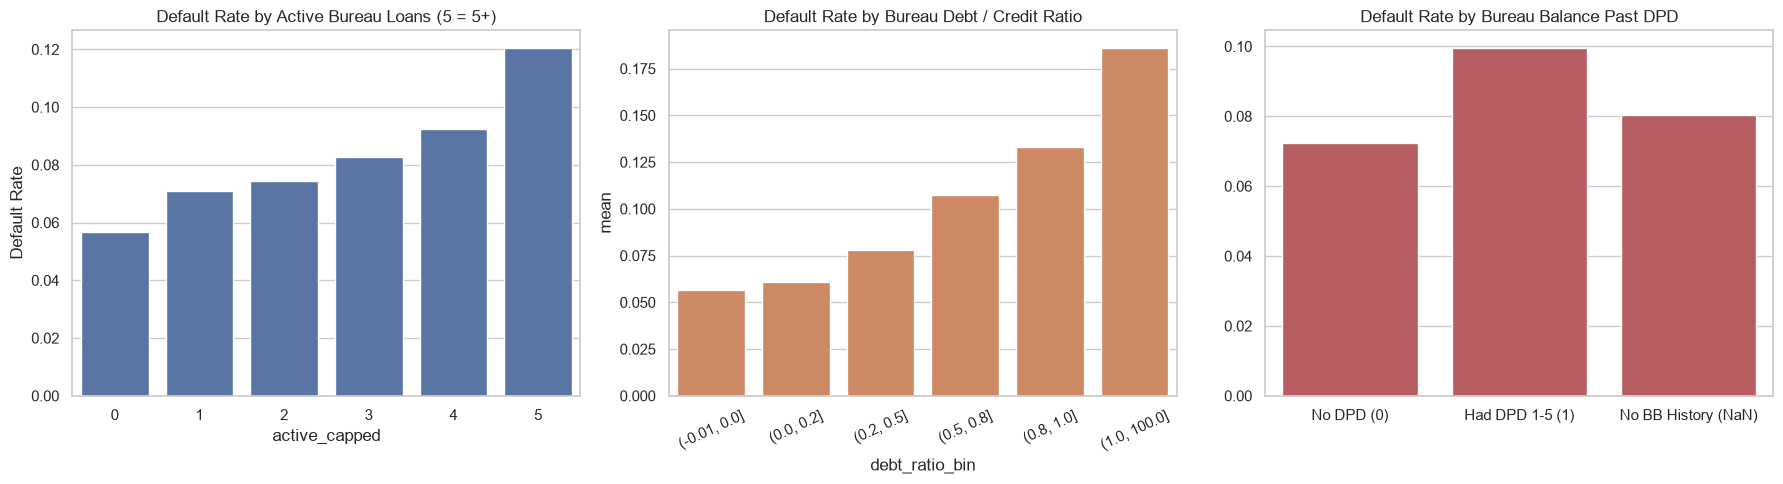

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Active loans count (capped at 5+)
df_b["active_capped"] = df_b["bureau_active_cnt"].clip(upper=5)
s1 = df_b.groupby("active_capped")["TARGET"].agg(["mean", "count"])
sns.barplot(x=s1.index.astype(int).astype(str), y=s1["mean"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Default Rate by Active Bureau Loans (5 = 5+)")
axes[0].set_ylabel("Default Rate")

# Bureau debt-to-credit ratio bins
df_b["debt_ratio_bin"] = pd.cut(df_b["bureau_debt_ratio"], bins=[-0.01, 0.0, 0.2, 0.5, 0.8, 1.0, 100])
s2 = df_b.groupby("debt_ratio_bin", observed=False)["TARGET"].agg(["mean", "count"])
sns.barplot(x=s2.index.astype(str), y=s2["mean"], ax=axes[1], color="#DD8452")
axes[1].set_title("Default Rate by Bureau Debt / Credit Ratio")
axes[1].tick_params(axis="x", rotation=25)

# Past DPD in bureau_balance
s3 = df_b.groupby("bb_ever_dpd", dropna=False)["TARGET"].agg(["mean", "count"])
labels = ["No DPD (0)", "Had DPD 1-5 (1)", "No BB History (NaN)"]
sns.barplot(x=labels[:len(s3)], y=s3["mean"].values, ax=axes[2], color="#C44E52")
axes[2].set_title("Default Rate by Bureau Balance Past DPD")

plt.tight_layout()
plt.show()

In [12]:
# Previous applications — exact 365243 audit & refusal rate signal
prev = pd.read_csv(
    DATA_DIR / "previous_application.csv",
    usecols=[
        "SK_ID_CURR", "SK_ID_PREV", "NAME_CONTRACT_STATUS",
        "AMT_APPLICATION", "AMT_CREDIT",
        "DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE",
        "DAYS_LAST_DUE_1ST_VERSION", "DAYS_LAST_DUE", "DAYS_TERMINATION",
    ],
)

# Check exact count of 365243 placeholders per DAYS_* column
days_cols = [c for c in prev.columns if c.startswith("DAYS_")]
anom_summary = pd.DataFrame({
    "count_365243": [(prev[c] == 365243).sum() for c in days_cols],
    "pct_365243": [f"{(prev[c] == 365243).mean():.1%}" for c in days_cols],
}, index=days_cols)
print("Placeholder 365243 in previous_application:")
display(anom_summary)

# Client-level refusal & approval ratios
prev["is_refused"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(np.int8)
prev["is_approved"] = (prev["NAME_CONTRACT_STATUS"] == "Approved").astype(np.int8)
prev["app_credit_ratio"] = prev["AMT_APPLICATION"] / prev["AMT_CREDIT"].replace(0, np.nan)

p_agg = prev.groupby("SK_ID_CURR").agg(
    prev_app_cnt=("SK_ID_PREV", "count"),
    prev_refused_cnt=("is_refused", "sum"),
    prev_refused_ratio=("is_refused", "mean"),
    prev_app_credit_ratio_mean=("app_credit_ratio", "mean"),
)

df_p = app_train.merge(p_agg, on="SK_ID_CURR", how="left")

Placeholder 365243 in previous_application:


,count_365243,pct_365243
DAYS_FIRST_DRAWING,934444,55.9%
DAYS_FIRST_DUE,40645,2.4%
DAYS_LAST_DUE_1ST_VERSION,93864,5.6%
DAYS_LAST_DUE,211221,12.6%
DAYS_TERMINATION,225913,13.5%


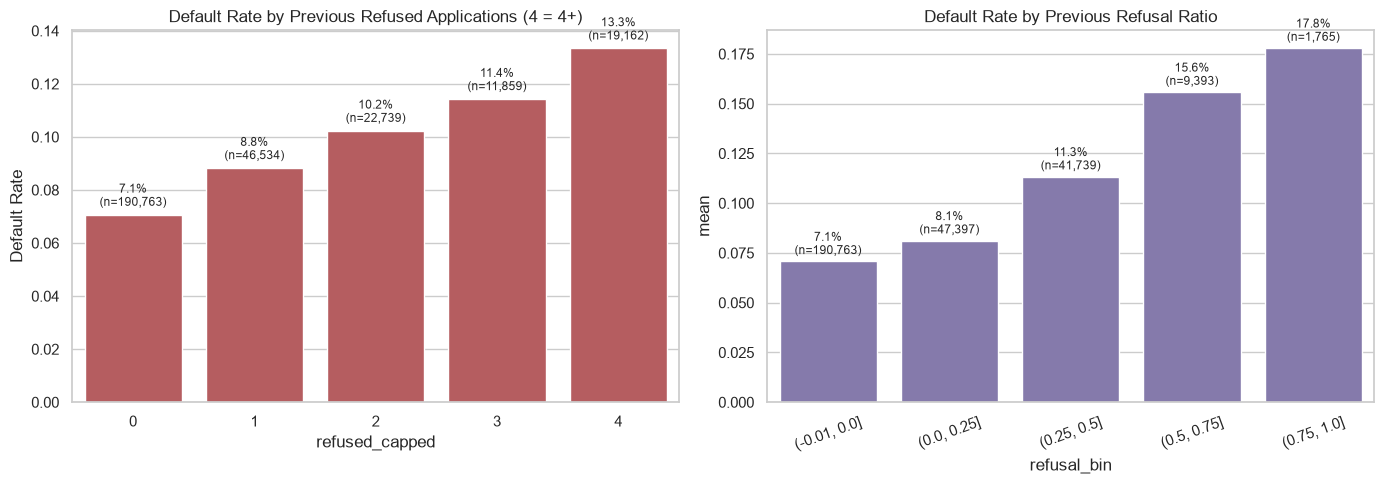

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Refused applications count (capped at 4+)
df_p["refused_capped"] = df_p["prev_refused_cnt"].clip(upper=4)
sp1 = df_p.groupby("refused_capped")["TARGET"].agg(["mean", "count"])
sns.barplot(x=sp1.index.astype(int).astype(str), y=sp1["mean"], ax=axes[0], color="#C44E52")
axes[0].set_title("Default Rate by Previous Refused Applications (4 = 4+)")
axes[0].set_ylabel("Default Rate")
for i, (rate, cnt) in enumerate(zip(sp1["mean"], sp1["count"])):
    axes[0].text(i, rate + 0.002, f"{rate:.1%}\n(n={cnt:,})", ha="center", va="bottom", fontsize=8.5)

# Refusal ratio buckets
df_p["refusal_bin"] = pd.cut(df_p["prev_refused_ratio"], bins=[-0.01, 0.0, 0.25, 0.5, 0.75, 1.0])
sp2 = df_p.groupby("refusal_bin", observed=False)["TARGET"].agg(["mean", "count"])
sns.barplot(x=sp2.index.astype(str), y=sp2["mean"], ax=axes[1], color="#8172B3")
axes[1].set_title("Default Rate by Previous Refusal Ratio")
axes[1].tick_params(axis="x", rotation=20)
for i, (rate, cnt) in enumerate(zip(sp2["mean"], sp2["count"])):
    axes[1].text(i, rate + 0.002, f"{rate:.1%}\n(n={cnt:,})", ha="center", va="bottom", fontsize=8.5)

plt.tight_layout()
plt.show()

In [14]:
# Payment discipline (installments) & Credit card utilization
inst = pd.read_csv(
    DATA_DIR / "installments_payments.csv",
    usecols=["SK_ID_CURR", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"],
)
inst["days_late"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)
inst["is_late"] = (inst["days_late"] > 0).astype(np.int8)
inst["is_underpaid"] = (inst["AMT_PAYMENT"] < inst["AMT_INSTALMENT"] - 1e-2).astype(np.int8)

inst_agg = inst.groupby("SK_ID_CURR").agg(
    inst_late_ratio=("is_late", "mean"),
    inst_underpaid_ratio=("is_underpaid", "mean"),
    inst_max_days_late=("days_late", "max"),
)

cc = pd.read_csv(
    DATA_DIR / "credit_card_balance.csv",
    usecols=["SK_ID_CURR", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL", "SK_DPD"],
)
cc["cc_utilization"] = cc["AMT_BALANCE"] / cc["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
cc_agg = cc.groupby("SK_ID_CURR").agg(
    cc_util_mean=("cc_utilization", "mean"),
    cc_max_dpd=("SK_DPD", "max"),
)

df_beh = app_train.merge(inst_agg, on="SK_ID_CURR", how="left").merge(cc_agg, on="SK_ID_CURR", how="left")

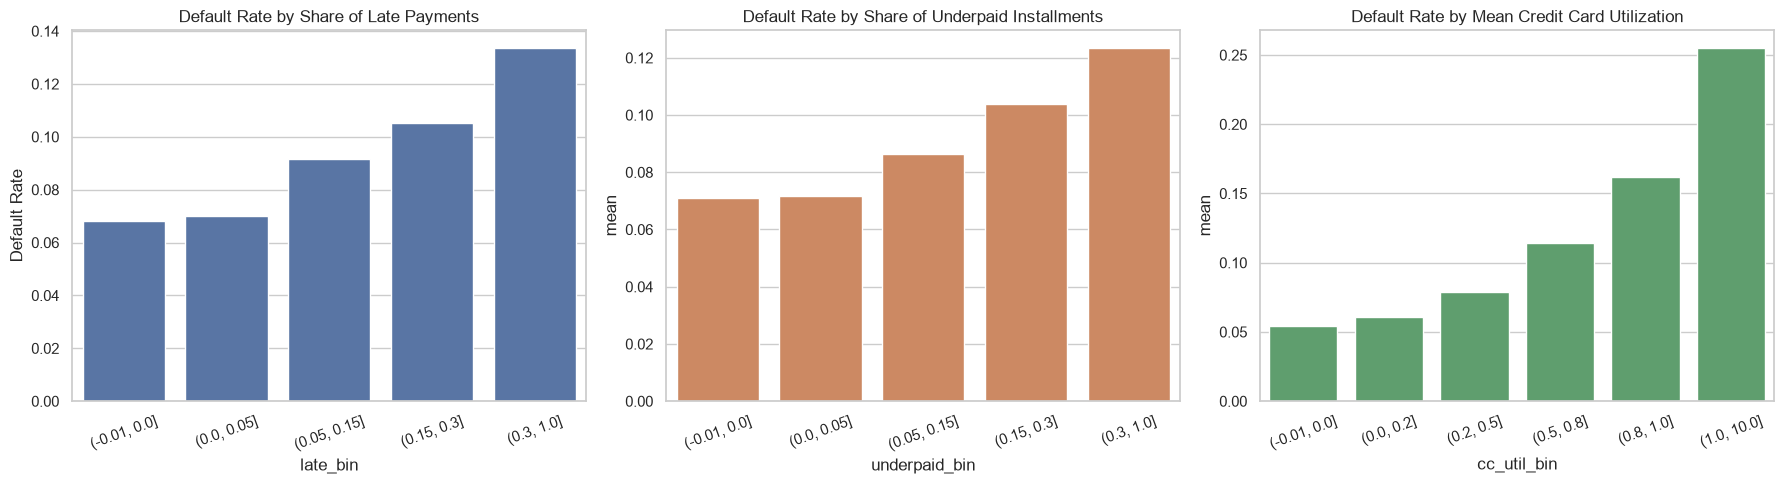

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Share of late installment payments
df_beh["late_bin"] = pd.cut(df_beh["inst_late_ratio"], bins=[-0.01, 0.0, 0.05, 0.15, 0.30, 1.0])
sb1 = df_beh.groupby("late_bin", observed=False)["TARGET"].agg(["mean", "count"])
sns.barplot(x=sb1.index.astype(str), y=sb1["mean"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Default Rate by Share of Late Payments")
axes[0].set_ylabel("Default Rate")
axes[0].tick_params(axis="x", rotation=20)

# Share of underpaid installments
df_beh["underpaid_bin"] = pd.cut(df_beh["inst_underpaid_ratio"], bins=[-0.01, 0.0, 0.05, 0.15, 0.30, 1.0])
sb2 = df_beh.groupby("underpaid_bin", observed=False)["TARGET"].agg(["mean", "count"])
sns.barplot(x=sb2.index.astype(str), y=sb2["mean"], ax=axes[1], color="#DD8452")
axes[1].set_title("Default Rate by Share of Underpaid Installments")
axes[1].tick_params(axis="x", rotation=20)

# Mean credit card utilization
df_beh["cc_util_bin"] = pd.cut(df_beh["cc_util_mean"], bins=[-0.01, 0.0, 0.2, 0.5, 0.8, 1.0, 10])
sb3 = df_beh.groupby("cc_util_bin", observed=False)["TARGET"].agg(["mean", "count"])
sns.barplot(x=sb3.index.astype(str), y=sb3["mean"], ax=axes[2], color="#55A868")
axes[2].set_title("Default Rate by Mean Credit Card Utilization")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Key Relational EDA Findings & Feature Engineering Plan

1. **Table Coverage & Opposite "History Presence" Signals:**
   - The 6 relational tables contain ~58M rows in total, with high client coverage in `previous_application` (`94.6%`), `installments_payments` (`94.8%`), `POS_CASH_balance` (`94.1%`), and `bureau` (`85.7%`), while `credit_card_balance` covers `28.3%` of applicants.
   - Missing history carries opposite risk signals depending on the source: clients *without* external `bureau` records are riskier (`10.12%` vs. `7.73%` — thin-file effect), whereas clients *without* prior internal history in `previous_application` / `installments_payments` have lower default rates (`5.96–5.98%` vs. `8.19%`).
   - *Action:* Preserve `NaN` values after left-joining relational aggregates so GBDT models capture history presence natively.

2. **External Credit Bureau (`bureau` & `bureau_balance`):**
   - Active external loans drive a monotonic 2.1x increase in default risk (`~5.7%` at 0 active loans → `~12.0%` at 5+ active loans).
   - Overall debt-to-credit ratio (`AMT_CREDIT_SUM_DEBT / AMT_CREDIT_SUM`) separates risk by 3.3x (`~5.6%` at zero debt → `~18.6%` when ratio > 1.0).
   - Historical DPD events in `bureau_balance` (statuses `1–5`) raise default risk to `~9.9%` vs. `~7.2%` for clients with clean payment records.
   - *Action:* Engineer overall and active-only bureau aggregations, client-level debt/overdue ratios, and 12-month / all-time DPD flags from `bureau_balance`.

3. **Previous Applications & Date Anomalies (`previous_application`):**
   - Prior rejections are a strong monotonic predictor: default rate rises from `7.1%` (0 refusals) to `13.3%` (4+ refusals), and reaches `17.8%` when the refusal ratio exceeds `75%`.
   - Systemic `365243` placeholders are confirmed across `DAYS_*` columns (`DAYS_FIRST_DRAWING`, `DAYS_FIRST_DUE`, `DAYS_LAST_DUE_1ST_VERSION`, `DAYS_LAST_DUE`, `DAYS_TERMINATION`); no `365243` values appear in the other 5 tables.
   - *Action:* Replace `365243` with `NaN` before aggregation and build separate feature blocks for overall, approved-only, and refused-only applications.

4. **Payment Discipline (`installments_payments` & `POS_CASH_balance`):**
   - Late payments (`>30%` of installments paid late) nearly double default risk (`~6.8%` → `~13.3%`), and underpayments (`>30%` underpaid) show a similar climb (`~7.1%` → `~12.3%`).
   - *Action:* Compute payment delay (`DAYS_LATE`, `DAYS_EARLY`), underpayment ratios, and POS DPD metrics across both full history and the **most recent 12 months**.

5. **Credit Card Utilization (`credit_card_balance`):**
   - Mean credit card utilization (`AMT_BALANCE / AMT_CREDIT_LIMIT_ACTUAL`) is the strongest single behavioral signal across all relational tables: default rate climbs from `~5.4%` (zero utilization) to `~16.2%` (`0.8–1.0`) and spikes to `~25.5%` for over-limit usage (`>1.0`).
   - *Action:* Engineer overall and 12-month utilization stats, over-limit flags, ATM cash-advance shares, and card DPD aggregations in `src/features_relational.py` for the `v2_relational` iteration.